# Figure 5

Redraws every data panel of Figure 5 from the source data workbook `Figure_5.xlsx`. Panel a is a schematic and has no data.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager

SOURCE = Path("..") / "Source data"                     # relative to this notebook's folder
BOOK = SOURCE / "Figure_5.xlsx"
# Boundary files are not redistributed; point GIS to a local copy (here the Dataset folder next to the repository).
GIS = Path("..") / ".." / "Dataset" / "GIS"
CITIES_SHP = GIS / "Prefecture City.shp"
BORDER_SHP = GIS / "guojie.shp"

FONT = "Calibri" if any(f.name == "Calibri" for f in font_manager.fontManager.ttflist) else "Carlito"
BASE, LETTER = 7.5, 10.5                                        # all text 7.5 pt; panel letters 10.5 pt bold
MM = 1 / 25.4
WIDTH = 180 * MM                                                # width of the published figure (in)
INK, INK3, GRIDC, NAVY = "#0b0b0b", "#76756f", "#eeeeec", "#22314a"
COL = {"local": "#2f6db5", "inbound": "#1a9e6f", "outbound": "#e86a33"}
TEAL, CORAL, GREY, LAND, EDGE = "#1795a3", "#d9644f", "#c7c6c1", "#f4f3f0", "#ffffff"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "mathtext.fontset": "custom",
    "mathtext.rm": FONT, "mathtext.it": f"{FONT}:italic", "mathtext.bf": f"{FONT}:bold",
    "mathtext.cal": FONT, "mathtext.sf": FONT, "mathtext.tt": FONT,
    "font.size": BASE, "axes.labelsize": BASE, "xtick.labelsize": BASE, "ytick.labelsize": BASE,
    "legend.fontsize": BASE, "axes.titlesize": BASE, "legend.title_fontsize": BASE, "legend.labelcolor": INK,
    "text.color": INK, "axes.edgecolor": INK3, "axes.linewidth": 0.5, "xtick.color": INK3, "ytick.color": INK3,
    "xtick.labelcolor": INK, "ytick.labelcolor": INK, "axes.labelcolor": INK,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
    "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
    "legend.frameon": False, "axes.unicode_minus": True,
    "figure.dpi": 300, "figure.facecolor": "white", "figure.edgecolor": "white", "savefig.facecolor": "white"})
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}


def panel_figure(x0, y0, w, h):
    """One panel as a standalone figure; positions are inches from the lower-left corner of the published figure."""
    fig = plt.figure(figsize=(w, h))

    def ax_in(x, y, ww, hh, **kw):
        return fig.add_axes([(x - x0) / w, (y - y0) / h, ww / w, hh / h], **kw)

    def letter(x, y, s):
        fig.text((x - x0) / w, (y - y0) / h, s, fontsize=LETTER, fontweight="bold", color=INK, va="top", ha="left")

    def T(x, y, s, **kw):
        kw.setdefault("fontsize", BASE)
        kw.setdefault("color", INK)
        return fig.text((x - x0) / w, (y - y0) / h, s, **kw)

    return fig, ax_in, letter, T


def overlay(ax_in, x0, y0, w, h):
    """Transparent axes covering the panel, with data coordinates in inches of the published figure."""
    ov = ax_in(x0, y0, w, h)
    ov.set_xlim(x0, x0 + w)
    ov.set_ylim(y0, y0 + h)
    ov.axis("off")
    ov.patch.set_alpha(0)
    return ov


def clean(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid:
        ax.grid(axis=grid, color=GRIDC, lw=0.5)
        ax.set_axisbelow(True)


def nfmt(v, nd=1):
    return f"{v:.{nd}f}".replace("-", "\u2212")


def mfmt(v, nd=1):
    return f"{v:+.{nd}f}".replace("-", "\u2212")


def pfmt(p):
    return r"$P$ < 0.001" if p < 0.001 else rf"$P$ = {p:.3f}" if p < 0.01 else rf"$P$ = {p:.2f}"

import geopandas as gpd
from pyproj import Transformer
from shapely.geometry import Point

CRS = "epsg:4793"
CUT = 1.95e6


def read_boundaries(simplify):
    """Prefecture polygons (projected, simplified) and the national border without the South China Sea dash set."""
    cities = gpd.read_file(CITIES_SHP).to_crs(CRS)
    cities["city_name"] = cities.city_name.str.strip()
    full = cities.copy()
    cities["geometry"] = cities.geometry.simplify(simplify)
    border = gpd.read_file(BORDER_SHP).to_crs(CRS)
    main = border[border.bounds["maxy"] >= CUT].copy()
    length = main.length
    chord = main.geometry.apply(lambda g: Point(g.coords[0]).distance(Point(g.coords[-1])))
    cen = main.geometry.centroid
    lat = np.asarray(Transformer.from_crs(CRS, "epsg:4326", always_xy=True).transform(cen.x.to_numpy(),
                                                                                      cen.y.to_numpy())[1])
    dash = (chord / length > 0.97) & length.between(100e3, 150e3) & (lat < 26)
    return cities, full, border, main.loc[~dash]


def south_china_sea_inset(ins, border):
    border.plot(ax=ins, color=INK3, linewidth=0.3)
    ins.set_xlim(0.10e6, 2.15e6)
    ins.set_ylim(0.0, 2.65e6)
    ins.set_aspect("equal")
    ins.set_xticks([])
    ins.set_yticks([])
    ins.set_xlabel("")
    ins.set_ylabel("")
    for s in ins.spines.values():
        s.set_linewidth(0.4)
        s.set_color(INK3)

from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from shapely.geometry import MultiPolygon, Polygon

HALO = [pe.withStroke(linewidth=2, foreground="white")]
L05_BREAKS = [300, 400, 500, 600]
L05_COLS = ["#efeaf6", "#d2c8e6", "#ad9dd1", "#8670b8", "#5e3c99"]
NODATA = "#e6e6e6"
MAIN_X, MAIN_Y = (-2.62e6, 2.62e6), (1.85e6, 6.15e6)
BIG5 = ["JJJ", "YRD", "PRD", "MYR", "CY"]
# grouping identity: key -> (colour, marker, size pt^2, filled)
ARR = {"province": (CORAL, "D", 16, True), "cluster": (CORAL, "s", 20, True), "demand": (CORAL, "*", 60, True),
       "eastwest": (INK, "h", 24, True), "random": (INK, "o", 20, False), "crossbelt": (TEAL, "^", 24, True)}
# layout of the published figure (in): panel a occupies the top; b and c share the middle row; d and e the bottom
MW = 3.14
MH = MW / ((MAIN_X[1] - MAIN_X[0]) / (MAIN_Y[1] - MAIN_Y[0]))
D_Y, D_H = 0.42, 1.22
MY = D_Y + D_H + 0.12 + 0.24                                    # bottom of the map (b) and of the table (c)
CTOP = MY + MH                                                  # top of the map
H = CTOP + 0.14 + 1.5352 + 0.04                                 # height of the published figure (panel a: 1.535 in)


def scat(ax, x, y, key, scale=1.0, z=6, **kw):
    col, mk, ms_, filled = ARR[key]
    return ax.scatter(np.atleast_1d(x), np.atleast_1d(y), s=ms_ * scale, marker=mk,
                      facecolor=col if filled else "white", edgecolor="white" if filled else col,
                      lw=0.4 if filled else 0.9, zorder=z, **kw)


def end_labels(ax, ends, gap, dx=0.4):
    """ends: [x, y, text, (x_label, y_label) or None]; same-x labels nudged apart; leaders where moved."""
    for xe in sorted(set(e_[0] for e_ in ends if e_[3] is None)):
        grp = sorted([e_ for e_ in ends if e_[0] == xe and e_[3] is None], key=lambda e_: e_[1])
        ys = [g_[1] for g_ in grp]
        for k in range(1, len(ys)):
            ys[k] = max(ys[k], ys[k - 1] + gap)
        for g_, yy in zip(grp, ys):
            ax.text(g_[0] + dx, yy, g_[2], fontsize=BASE, ha="left", va="center", zorder=8, clip_on=False)
    for x_, y_, t_, pos in ends:
        if pos is not None:
            ax.annotate(t_, (x_, y_), xytext=pos, fontsize=BASE, ha="left", va="center", zorder=8,
                        annotation_clip=False, arrowprops=dict(arrowstyle="-", lw=0.5, color=INK3, shrinkA=1,
                                                               shrinkB=1.5))


def peak_axis(ax):
    clean(ax, "y")
    ax.set_xlim(1.4, 20.6)
    ax.set_xticks([2, 5, 10, 15, 20])
    ax.set_xlabel("Number of cities in the group")
    ax.set_ylabel("Excess peak shortfall")

**Panel b** (map): decoupling distance L05 of each prefecture unit, with the five national-level city clusters.

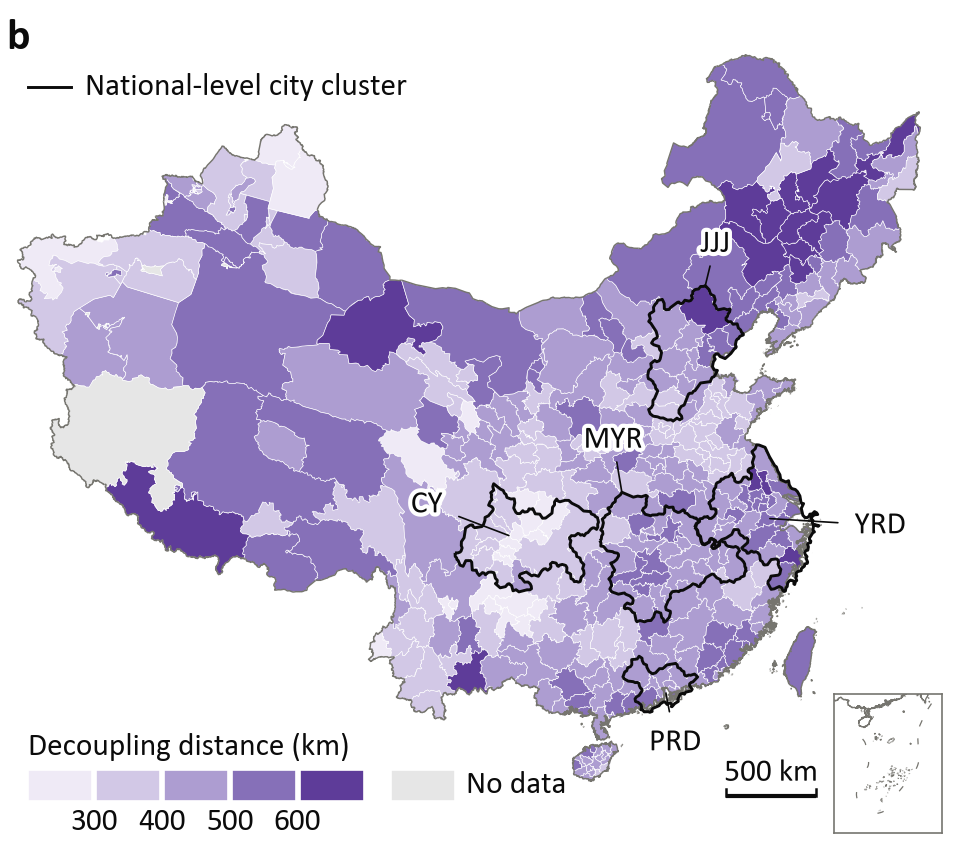

In [2]:
units = pd.read_excel(BOOK, sheet_name="Fig5b")
members = pd.read_excel(BOOK, sheet_name="Fig5b_clusters")

X0, Y0, PW, PH = 0.0, 1.86, 3.24, 2.84
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
cities, full, border, border_main = read_boundaries(3000)
full["cluster"] = full.city_name.map(dict(zip(members.city_name, members.cluster)))
outlines = {}
for k in BIG5:
    geom = full.loc[full.cluster == k].geometry.buffer(12000).union_all().buffer(-12000).simplify(2500)
    polys = [Polygon(p.exterior) for p in (geom.geoms if isinstance(geom, MultiPolygon) else [geom]) if p.area > 5e8]
    outlines[k] = MultiPolygon(polys) if len(polys) > 1 else polys[0]
axb = ax_in(0.0, MY, MW, MH)
letter(0.02, MY + MH + 0.06, "b")
m = cities.merge(units[["unit_name", "L05_class"]], left_on="city_name", right_on="unit_name", how="left")
m["col"] = [L05_COLS[int(k)] if pd.notna(k) and k >= 0 else NODATA for k in m.L05_class]
m.plot(ax=axb, color=m.col, edgecolor=EDGE, linewidth=0.15, zorder=1)
border_main.plot(ax=axb, color=INK3, linewidth=0.35, zorder=4)
axb.set_xlim(*MAIN_X)
axb.set_ylim(*MAIN_Y)
axb.set_aspect("equal")
axb.axis("off")
OFF = {"YRD": (6.6e5, -0.4e5), "PRD": (0.6e5, -3.2e5), "CY": (-5.0e5, 1.9e5)}
ABS = {"JJJ": (1.36e6, 5.00e6), "MYR": (0.79e6, 3.91e6)}
for k in BIG5:
    geom = outlines[k]
    gpd.GeoSeries([geom], crs=CRS).boundary.plot(ax=axb, color=INK, linewidth=0.7, zorder=6)
    p = geom.representative_point()
    if k in ABS:
        lab_ = Point(*ABS[k])
        p = geom.boundary.interpolate(geom.boundary.project(lab_))
        OFF[k] = (lab_.x - p.x, lab_.y - p.y)
    axb.annotate(k, xy=(p.x, p.y), xytext=(p.x + OFF[k][0], p.y + OFF[k][1]), fontsize=BASE, color=INK,
                 ha="center", va="center", path_effects=HALO,
                 arrowprops=dict(arrowstyle="-", lw=0.4, color=INK, shrinkA=0 if k in ABS else 2,
                                 shrinkB=0 if k in ABS else 2), zorder=9)
fig.canvas.draw()
pos = axb.get_position()
FW, FH = fig.get_size_inches()
aw, ah = pos.width * FW, pos.height * FH
rr = (MAIN_X[1] - MAIN_X[0]) / (MAIN_Y[1] - MAIN_Y[0])
mw, mh = (aw, aw / rr) if aw / ah < rr else (ah * rr, ah)
sc_ = MH / 2.87
ins = fig.add_axes([(pos.x0 * FW + (aw + mw) / 2 - 0.40 * sc_) / FW, (pos.y0 * FH + (ah - mh) / 2 - 0.12 * sc_) / FH,
                    0.40 * sc_ / FW, 0.585 * sc_ / FH])
south_china_sea_inset(ins, border)
lx, ly, bw, bh = 0.03, 0.012, 0.072, 0.040
for i, col in enumerate(L05_COLS):
    axb.add_patch(Rectangle((lx + i * bw, ly), bw - 0.004, bh, transform=axb.transAxes, color=col, ec="white",
                            lw=0.4, zorder=9))
for i, t in enumerate(L05_BREAKS, start=1):
    axb.text(lx + i * bw - 0.002, ly - 0.010, f"{t}", transform=axb.transAxes, fontsize=BASE, ha="center",
             va="top", zorder=9)
nx = lx + 5 * bw + 0.025
axb.add_patch(Rectangle((nx, ly), bw - 0.004, bh, transform=axb.transAxes, color=NODATA, ec="white", lw=0.4, zorder=9))
axb.text(nx + bw + 0.008, ly + bh / 2, "No data", transform=axb.transAxes, fontsize=BASE, ha="left", va="center",
         zorder=9)
axb.text(lx, ly + bh + 0.012, "Decoupling distance (km)", transform=axb.transAxes, fontsize=BASE, ha="left",
         va="bottom", zorder=9)
ex, ey = 0.03, 0.935
axb.add_line(Line2D([ex, ex + 0.045], [ey, ey], transform=axb.transAxes, color=INK, lw=0.7, zorder=9))
axb.text(ex + 0.06, ey, "National-level city cluster", transform=axb.transAxes, fontsize=BASE, ha="left",
         va="center", zorder=9)
sx0, sy0 = 1.42e6, 1.93e6
axb.add_line(Line2D([sx0, sx0 + 5e5], [sy0, sy0], color=INK, lw=1.0, solid_capstyle="butt", zorder=9))
for xx in (sx0, sx0 + 5e5):
    axb.add_line(Line2D([xx, xx], [sy0, sy0 + 3.5e4], color=INK, lw=0.6, zorder=9))
axb.text(sx0 + 2.5e5, sy0 + 5.0e4, "500 km", fontsize=BASE, ha="center", va="bottom", zorder=9, path_effects=HALO)
plt.show()

**Panel c**: group S, synchrony of shortfalls (VR) and VR per +0.1 S for six ways of forming groups of five cities.

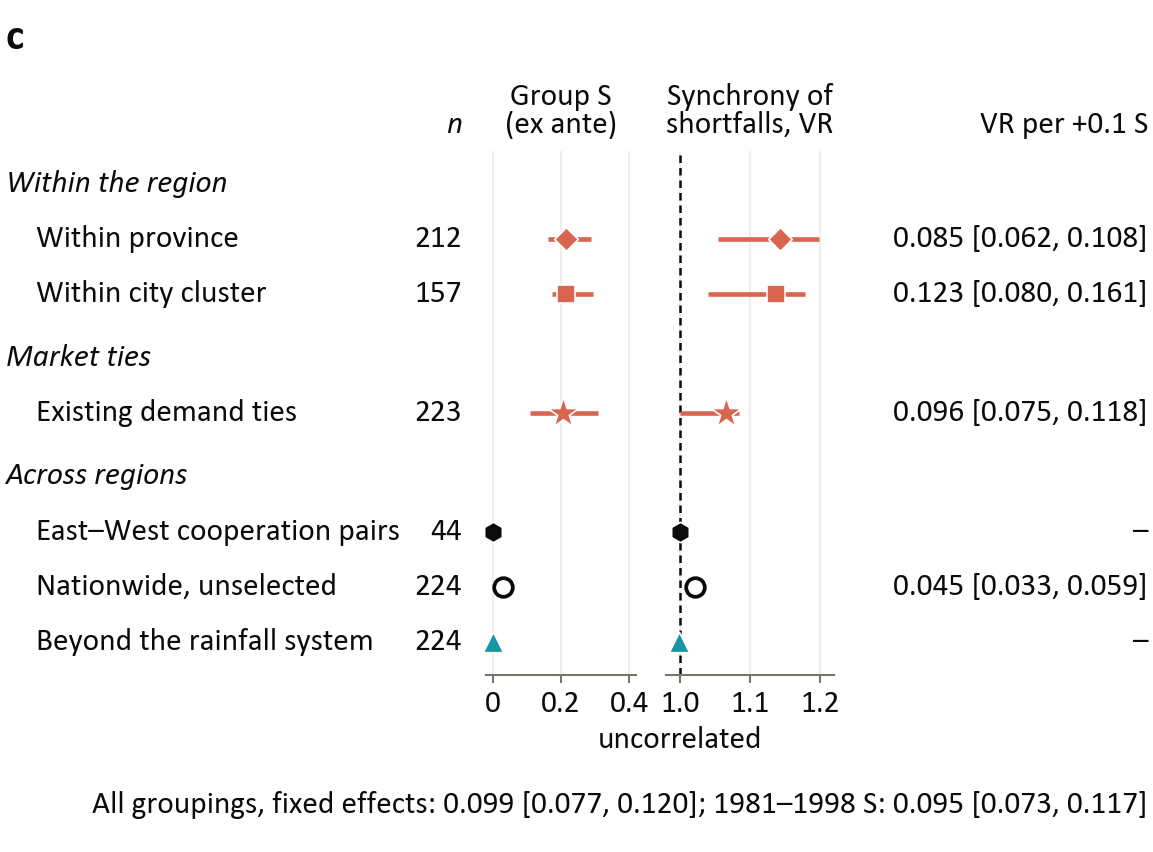

In [3]:
tab = pd.read_excel(BOOK, sheet_name="Fig5c").sort_values("row_order")
fe = pd.read_excel(BOOK, sheet_name="Fig5c_fixed_effects").set_index("S_period")

X0, Y0, PW, PH = 3.24, 1.86, WIDTH - 3.24, 2.84
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
CX0 = 3.26
letter(CX0, CTOP + 0.06, "c")
X, Y, Wd, Hd = CX0, MY - 0.05, WIDTH - CX0, CTOP - MY + 0.05
rows, yy = [], 0.0
for head in tab.group_header.unique():
    rows.append(("head", head, yy))
    yy -= 1.0
    for r in tab.loc[tab.group_header == head].itertuples():
        rows.append(("row", r, yy))
        yy -= 1.0
    yy -= 0.15
ymin, ymax = yy + 0.55, 0.6
XL, XN = X + 0.0, X + 1.52
SX, SW, VX, VW, XT = X + 1.60, 0.50, X + 2.20, 0.56, X + Wd - 0.02
AY, AH = Y + 0.50, Hd - 0.50 - 0.38
axS, axV = ax_in(SX, AY, SW, AH), ax_in(VX, AY, VW, AH)
for ax_ in (axS, axV):
    clean(ax_, "x")
    ax_.spines["left"].set_visible(False)
    ax_.set_yticks([])
    ax_.set_ylim(ymin, ymax)
axS.set_xlim(-0.02, 0.42)
axS.set_xticks([0, 0.2, 0.4])
axS.set_xticklabels(["0", "0.2", "0.4"])
axV.set_xlim(0.98, 1.22)
axV.set_xticks([1.0, 1.1, 1.2])
axV.set_xticklabels(["1.0", "1.1", "1.2"])
axV.axvline(1.0, color=INK, lw=0.6, ls=(0, (3, 2)), zorder=1)
fy = lambda v: AY + AH * (v - ymin) / (ymax - ymin)
for kind, r, y in rows:
    if kind == "head":
        T(XL, fy(y), r, ha="left", va="center", style="italic")
        continue
    col = ARR[r.grouping_key][0]
    T(XL + 0.10, fy(y), r.grouping, ha="left", va="center")
    T(XN, fy(y), f"{int(r.n_focal_cities)}", ha="right", va="center")
    axS.plot([r.group_S_p25, r.group_S_p75], [y, y], color=col, lw=1.1, solid_capstyle="butt", zorder=3)
    scat(axS, r.group_S_median, y, r.grouping_key, z=5, clip_on=False)
    if pd.notna(r.VR_median):
        if pd.notna(r.VR_ci_low) and pd.notna(r.VR_ci_high):
            axV.plot([r.VR_ci_low, r.VR_ci_high], [y, y], color=col, lw=1.1, solid_capstyle="butt", zorder=3)
        scat(axV, r.VR_median, y, r.grouping_key, z=5)
    else:
        T(VX + VW * (1.05 - 0.98) / 0.24, fy(y), "\u2013", ha="center", va="center")
    if pd.notna(r.VR_slope_per_0p1_S):
        st = f"{r.VR_slope_per_0p1_S:.3f} [{r.VR_slope_ci_low:.3f}, {r.VR_slope_ci_high:.3f}]".replace("-", "\u2212")
    else:
        st = "\u2013"
    T(XT, fy(y), st, ha="right", va="center")
top = AY + AH + 0.04
T(XN, top, "n", ha="right", va="bottom", style="italic")
T(SX + SW / 2, top, "Group S\n(ex ante)", ha="center", va="bottom", linespacing=1.0)
T(VX + VW / 2, top, "Synchrony of\nshortfalls, VR", ha="center", va="bottom", linespacing=1.0)
T(XT, top, "VR per +0.1 S", ha="right", va="bottom")
T(VX + VW * (1.0 - 0.98) / 0.24, AY - 0.17, "uncorrelated", ha="center", va="top")
a_, b_ = fe.loc["1981–2016"], fe.loc["1981–1998"]
T(XT, Y + 0.02, f"All groupings, fixed effects: {a_.VR_slope_per_0p1_S:.3f} [{a_.ci_low:.3f}, {a_.ci_high:.3f}]; "
  f"1981\u20131998 S: {b_.VR_slope_per_0p1_S:.3f} [{b_.ci_low:.3f}, {b_.ci_high:.3f}]", ha="right", va="bottom")
plt.show()

**Panel d**: excess peak shortfall against the number of cities in the group, for four ways of forming groups.

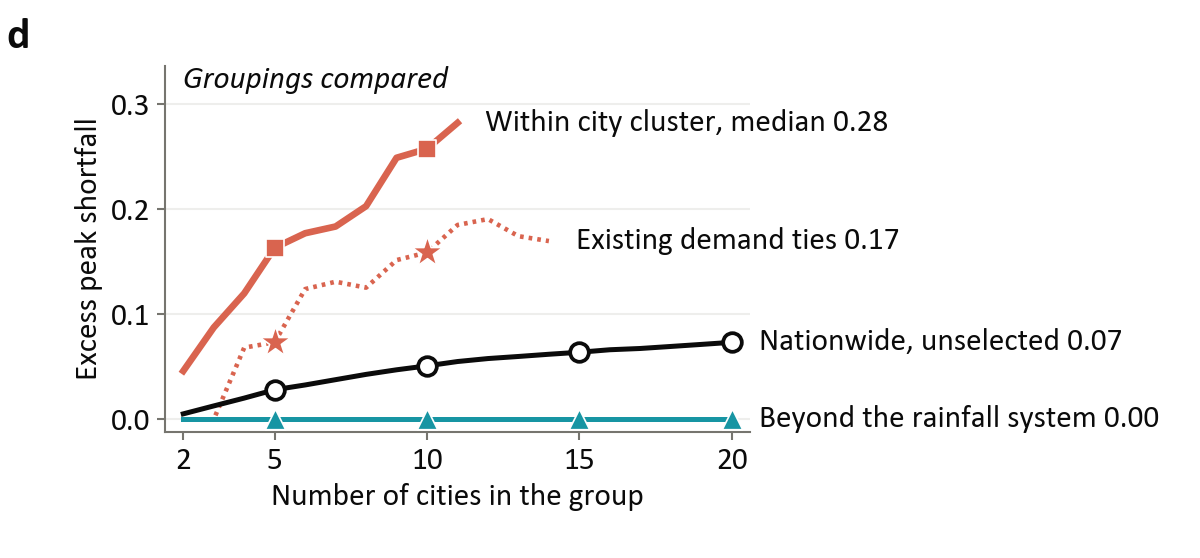

In [4]:
ps = pd.read_excel(BOOK, sheet_name="Fig5d")

X0, Y0, PW, PH = 0.0, 0.0, 4.0, 1.86
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
letter(0.02, D_Y + D_H + 0.16, "d")
axA = ax_in(0.55, D_Y, 1.95, D_H)
peak_axis(axA)
SER = [("cluster", "-", 1.6, "Within city cluster, median"), ("demand", (0, (0.8, 1.1)), 1.1, "Existing demand ties"),
       ("random", "-", 1.2, "Nationwide, unselected"), ("crossbelt", "-", 1.2, "Beyond the rainfall system")]
endsA, ymaxA = [], 0.0
for key, ls, lw, short in SER:
    q = ps.loc[ps.grouping_key == key].sort_values("n_cities_in_group")
    col = ARR[key][0]
    axA.plot(q.n_cities_in_group, q.excess_peak_shortfall_median, color=col, lw=lw, ls=ls, zorder=4)
    mk = q.loc[q.n_cities_in_group.isin([5, 10, 15, 20])]
    scat(axA, mk.n_cities_in_group, mk.excess_peak_shortfall_median, key, z=6, clip_on=False)
    ymaxA = max(ymaxA, float(q.excess_peak_shortfall_median.max()))
    e = q.iloc[-1]
    endsA.append([float(e.n_cities_in_group), float(e.excess_peak_shortfall_median),
                  f"{short} {nfmt(e.excess_peak_shortfall_median, 2)}", None])
topA = np.ceil(ymaxA / 0.1 - 1e-9) * 0.1
yrA = topA * 1.12
axA.set_ylim(-0.04 * topA, yrA)
axA.set_yticks(np.round(np.arange(0, topA + 1e-9, 0.1), 1))
axA.set_yticklabels([nfmt(v, 1) for v in np.arange(0, topA + 1e-9, 0.1)])
end_labels(axA, endsA, 0.09 * yrA, dx=0.9)
axA.text(2.0, yrA, "Groupings compared", fontsize=BASE, ha="left", va="top", style="italic")
plt.show()

**Panel e**: excess peak shortfall against the number of cities in the group, within each national-level city cluster.

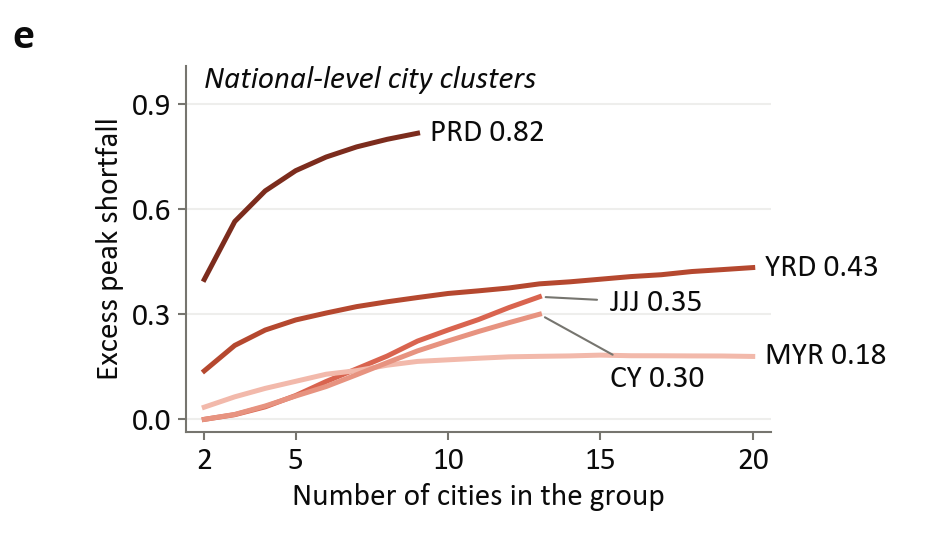

In [5]:
bc = pd.read_excel(BOOK, sheet_name="Fig5e")

X0, Y0, PW, PH = 4.0, 0.0, WIDTH - 4.0, 1.86
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
XR = 4.62
letter(XR - 0.58, D_Y + D_H + 0.16, "e")
axC = ax_in(XR, D_Y, 1.95, D_H)
peak_axis(axC)
ends_ = {k: bc.loc[bc.cluster == k].sort_values("n_cities_in_group").iloc[-1] for k in BIG5}
order = sorted(BIG5, key=lambda k: float(ends_[k].excess_peak_shortfall_median))
GRAD = ["#f2b9ab", "#e79380", "#d9644f", "#b5482f", "#7c2c1d"]
endsC = []
for k in BIG5:
    q = bc.loc[bc.cluster == k].sort_values("n_cities_in_group")
    axC.plot(q.n_cities_in_group, q.excess_peak_shortfall_median, color=GRAD[order.index(k)], lw=1.2, zorder=3)
    e = q.iloc[-1]
    endsC.append([float(e.n_cities_in_group), float(e.excess_peak_shortfall_median),
                  f"{k} {nfmt(e.excess_peak_shortfall_median, 2)}", None])
ymaxC = float(bc.excess_peak_shortfall_median.max())
topC = np.ceil(ymaxC / 0.3 - 1e-9) * 0.3
yrC = topC * 1.12
axC.set_ylim(-0.04 * topC, yrC)
tC = np.round(np.arange(0, topC + 1e-9, 0.3), 1)
axC.set_yticks(tC)
axC.set_yticklabels([nfmt(v, 1) for v in tC])
gap = 0.085 * yrC
byx = {}
for e_ in endsC:
    byx.setdefault(e_[0], []).append(e_)
for xe, grp in byx.items():
    if xe < 20 and len(grp) > 1:                                # clusters ending at the same group size
        grp = sorted(grp, key=lambda e_: -e_[1])
        for j_, e_ in enumerate(grp):
            e_[3] = (xe + 2.3, e_[1] - 0.2 * gap - j_ * 1.15 * gap)
        grp[-1][3] = (xe + 2.3, 0.115 * topC / 0.9)
end_labels(axC, endsC, gap)
axC.text(2.0, yrC, "National-level city clusters", fontsize=BASE, ha="left", va="top", style="italic")
plt.show()